# ARIMA — Checkpoint (week 4)

Maak per dataset een ARIMA-analyse met grid search naar optimale (p,d,q)-parameters.

## BELANGRIJK: gebruik exact de genoemde variabelennamen
De checks (`checks/test_week04.py`) voeren dit notebook uit en controleren volgende
variabelen. Gebruik exact deze namen, anders falen de checks:

- Oefening 1 (TF_BIRTHS): `series_births`, `births_2022_daily`, `monthly_births`,
  `best_order_births`, `rmse_births`
- Oefening 2 (AQI Duitsland): `aqi_germany`, `aqi_filtered`, `best_order_aqi`, `rmse_aqi`
- Oefening 3 (Electric Production): `series_electric`, `best_order_electric`, `rmse_electric`
- Meerkeuze: `antwoord_adf`, `antwoord_seizoen_births` (waarde "A", "B", "C" of "D")

Conventies die de checks gebruiken: alle grid searches met `p_values = [0, 1, 2, 4]`,
`d_values = [0, 1]`, `q_values = [0, 1]` en een 66/34 train/test-split
(`train_size = int(len(X) * 0.66)`) zoals in de gegeven helperfuncties.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from math import sqrt
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

def evaluate_arima_model(X, arima_order):
    """Walk-forward validatie: RMSE van een ARIMA(order) op reeks X (66/34-split)."""
    X = np.asarray(X, dtype="float32").ravel()
    train_size = int(len(X) * 0.66)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=arima_order)
        model_fit = model.fit()
        predictions.append(model_fit.forecast()[0])
        history.append(test[t])
    return sqrt(mean_squared_error(test, predictions))

def grid_search_arima(X, p_values, d_values, q_values):
    """Zoekt beste (p,d,q) via walk-forward RMSE. Geeft (best_order, best_rmse)."""
    best_score, best_cfg = float("inf"), None
    for p in p_values:
        for d in d_values:
            for q in q_values:
                try:
                    rmse = evaluate_arima_model(X, (p, d, q))
                except Exception:
                    continue
                if rmse < best_score:
                    best_score, best_cfg = rmse, (p, d, q)
    return best_cfg, best_score

p_values = [0, 1, 2, 4]
d_values = [0, 1]
q_values = [0, 1]


## Oefening 1 — TF_BIRTHS (geboortecijfers België)

1. Laad `./data/TF_BIRTHS.csv` in (scheidingsteken `;`) en hernoem de kolom
   `MS_NUM_BIRTHS` naar `value`. Parse de eerste kolom (`DT_DATE`, formaat
   `%d/%m/%Y`) als index. Sla op in **`series_births`** (DataFrame).
2. Maak **`births_2022_daily`**: enkel de dagcijfers van 2022. Maak een plot en
   bekijk het histogram van de dagcijfers — wat valt op? Hoe komt dat ?
3. Maak **`monthly_births`**: de volledige reeks hersamplet naar maanden (som).
   Welk seizoenspatroon zie je? (beantwoord de meerkeuzevraag verderop)
4. Test met de ADF-test of de maandreeks stationair is.
5. Zoek met grid search de beste ARIMA-parameters voor de maandreeks en sla op in
   **`best_order_births`** (tuple) en de bijhorende walk-forward RMSE in
   **`rmse_births`**.
6. Fit het finale model en plot de residuals.


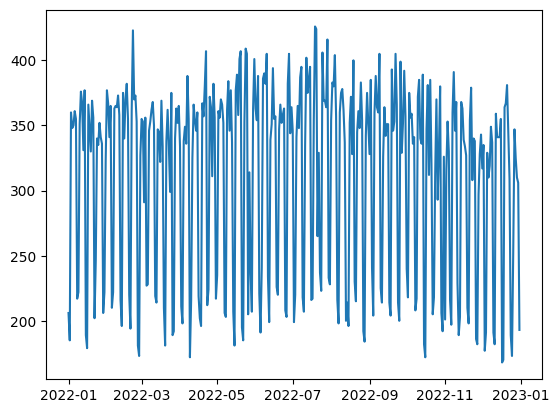

DT_DATE
2022-01-31    9446
2022-02-28    8914
2022-03-31    9639
2022-04-30    9214
2022-05-31    9848
Freq: ME, Name: value, dtype: int64


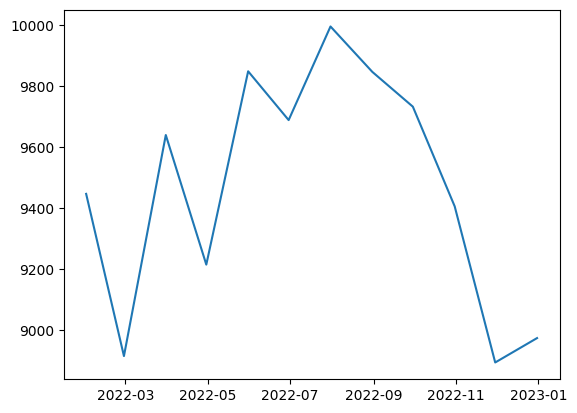

ADF statistiek: -2.083826
p-waarde: 0.251068
((4, 1, 1), 56.500267905891384)
56.500267905891384


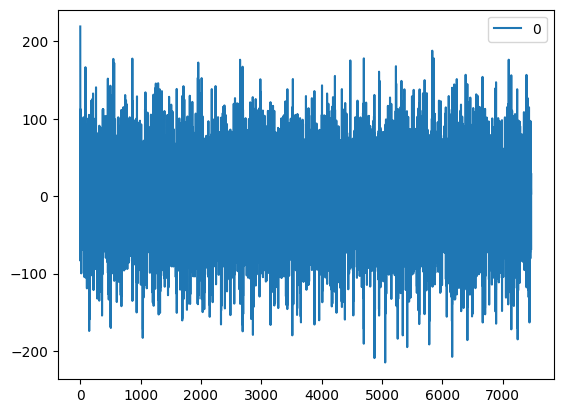

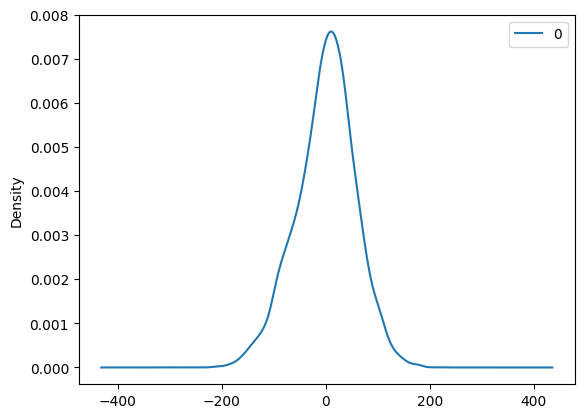

In [2]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
# 1
series_births = pd.read_csv('./data/TF_BIRTHS.csv', sep=';')
series_births.rename(columns={'MS_NUM_BIRTHS': 'value'}, inplace=True)
series_births.index = pd.to_datetime(series_births['DT_DATE'], format='%d/%m/%Y')
series_births.drop(columns=['DT_DATE'], inplace=True)
# print(series_births.head(5))

# 2
births_2022_daily = series_births.loc[(series_births.index >= '2022-01-01') & (series_births.index < '2023-01-01')]
plt.plot(births_2022_daily.index, births_2022_daily['value'])
plt.show()

# 3
monthly_births = births_2022_daily['value'].resample('ME').sum()
print(monthly_births.head(5))
plt.plot(monthly_births.index, monthly_births)
plt.show()

# 4
adf_check = adfuller(births_2022_daily.dropna())
print('ADF statistiek: %f' % adf_check[0])
print('p-waarde: %f' % adf_check[1])

# 5
best_order_births = grid_search_arima(births_2022_daily, p_values, d_values, q_values)
print(best_order_births)
rmse_births = evaluate_arima_model(births_2022_daily, arima_order=best_order_births[0])
print(rmse_births)

# 6
X = series_births.values
# print(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
model = ARIMA(history, order=best_order_births[0])
model_fit = model.fit()

# line plot of residuals
residuals = pd.DataFrame(model_fit.resid)
residuals.plot()
plt.show()
# density plot of residuals
residuals.plot(kind='kde')
plt.show()

## Oefening 2 — AQI: luchtkwaliteit Duitsland

1. Laad `./data/data_date.csv` in (eerste kolom = datum-index).
2. Filter op `Country == 'Germany'` en hou enkel de kolom `AQI Value` (hernoemd naar
   `value`). Sla op in **`aqi_germany`**.
3. Filter de data tussen 21 juli 2022 en 22 september 2022 → **`aqi_filtered`**.
4. Test met de ADF-test of de reeks stationair is (beantwoord daarna de
   meerkeuzevraag `antwoord_adf`).
5. Grid search → **`best_order_aqi`** en **`rmse_aqi`**. Fit het finale model en
   plot de residuals.


              Country                          Status  AQI Value
Date                                                            
2022-07-21    Albania                            Good         14
2022-07-21    Algeria                        Moderate         65
2022-07-21    Andorra                        Moderate         55
2022-07-21     Angola  Unhealthy for Sensitive Groups        113
2022-07-21  Argentina                        Moderate         63
Country      object
Status       object
AQI Value     int64
dtype: object
ADF statistiek: -4.119410
p-waarde: 0.000899
Best order: ((1, 0, 0), 11.382518253961107)
RMSE: 11.382518253961107
[[77]
 [79]
 [58]
 [61]
 [66]]


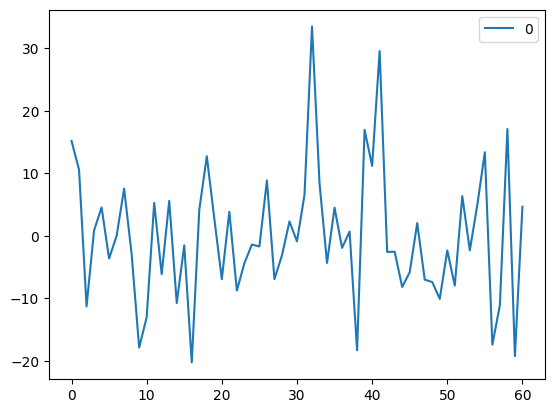

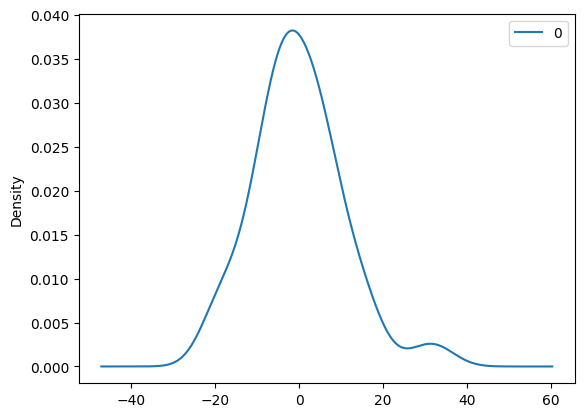

In [29]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
df = pd.read_csv('./data/data_date.csv', index_col=[0])
print(df.head(5))

aqi_germany = df[df['Country'] == 'Germany']
print(aqi_germany.dtypes)
aqi_germany.drop(columns=['Country', 'Status'], inplace=True)
aqi_germany.rename(columns={'AQI Value': 'value'})

aqi_filtered = aqi_germany.loc[(aqi_germany.index >= '2022-07-21') & (aqi_germany.index <= '2022-09-22')]

# 4
adf_check = adfuller(aqi_filtered.dropna())
print('ADF statistiek: %f' % adf_check[0])
print('p-waarde: %f' % adf_check[1])

# 5
best_order_aqi = grid_search_arima(aqi_filtered, p_values, [0], q_values)
print(f'Best order: {best_order_aqi}')
rmse_aqi = evaluate_arima_model(aqi_filtered, best_order_aqi[0])
print(f'RMSE: {rmse_aqi}')

X = aqi_germany.values
print(X[:5])
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
model = ARIMA(history, order=best_order_aqi[0])
model_fit = model.fit()

# line plot of residuals
residuals = pd.DataFrame(model_fit.resid)
residuals.plot()
plt.show()
# density plot of residuals
residuals.plot(kind='kde')
plt.show()

## Oefening 3 — Electric Production

1. Laad `./data/Electric_Production.xls` in (het is effectief een CSV; eerste kolom =
   datum-index) en hernoem `Value` naar `value` → **`series_electric`**.
2. Bekijk de reeks: hier is duidelijk een trend én een seizoenspatroon, dus `d = 1`
   is een goede keuze voor de differencing.
3. Grid search → **`best_order_electric`** en **`rmse_electric`**. Fit het finale
   model en plot walk-forward voorspellingen tegen de testset.


              value
DATE               
1985-01-01  72.5052
1985-02-01  70.6720
1985-03-01  62.4502
1985-04-01  57.4714
1985-05-01  55.3151


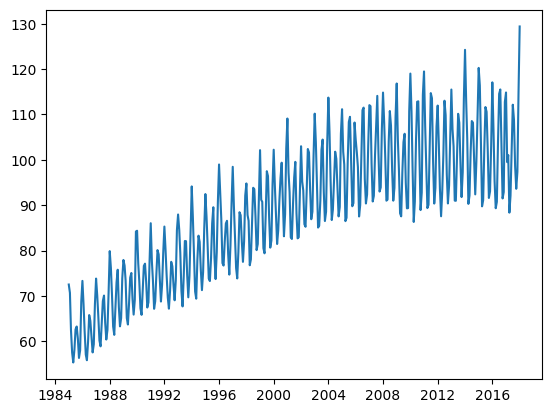

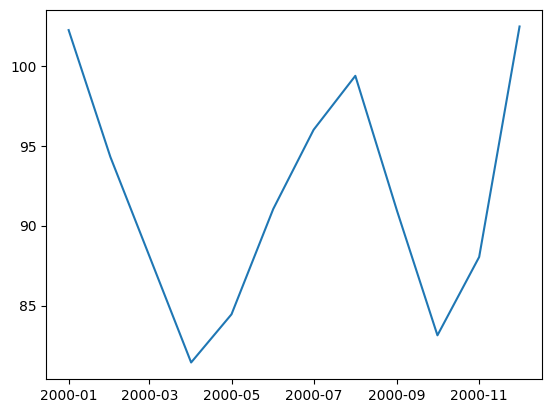

Best order: ((4, 1, 1), 4.399362145052985)
RMSE: 4.399362145052985
[[72.5052]
 [70.672 ]
 [62.4502]
 [57.4714]
 [55.3151]]


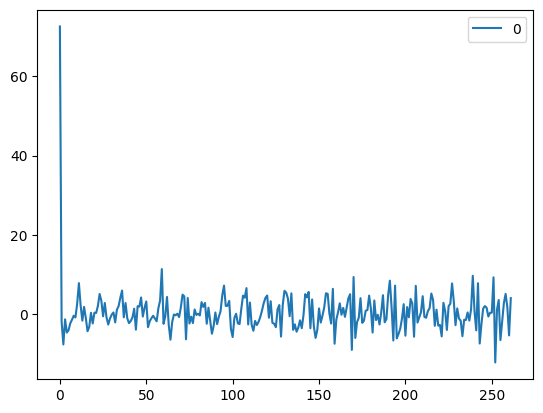

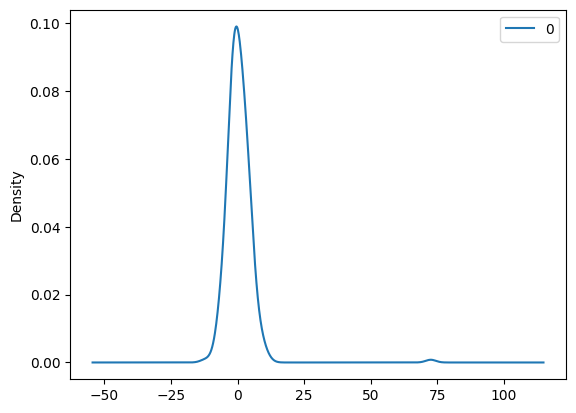

In [30]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
# 1
series_electric = pd.read_csv('./data/Electric_Production.xls')
series_electric.index = pd.to_datetime(series_electric['DATE'])
series_electric.drop(columns=['DATE'], inplace=True)
series_electric.rename(columns={'Value': 'value'}, inplace=True)
print(series_electric.head(5))

# 2
plt.plot(series_electric)
plt.show()

plt.plot(series_electric.loc[(series_electric.index >= '2000-01-01') & (series_electric.index < '2001-01-01')])
plt.show()

# 3
best_order_electric = grid_search_arima(series_electric, p_values, [1], q_values)
print(f'Best order: {best_order_electric}')
rmse_electric = evaluate_arima_model(series_electric, best_order_electric[0])
print(f'RMSE: {rmse_electric}')

X = series_electric.values
print(X[:5])
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
model = ARIMA(history, order=best_order_electric[0])
model_fit = model.fit()

# line plot of residuals
residuals = pd.DataFrame(model_fit.resid)
residuals.plot()
plt.show()
# density plot of residuals
residuals.plot(kind='kde')
plt.show()

## Meerkeuzevragen

**Vraag 1 (ADF):** de p-waarde van de ADF-test op de gefilterde AQI-reeks van Duitsland
is kleiner dan 0.05. Wat betekent dit?

- A) De reeks is niet-stationair; er is differencing nodig
- B) De reeks is stationair; differencing is niet nodig
- C) De reeks heeft een sterke trend
- D) De ADF-test zegt niets over stationariteit

**Vraag 2 (seizoen geboortes):** welk seizoenspatroon zie je in de maandelijkse
geboortecijfers van België?

- A) Geen enkel seizoenspatroon
- B) Een piek rond juli-september
- C) Enkel een piek in december
- D) Een lineair dalende trend zonder seizoenen


In [5]:
# Vraag 1: vul "A", "B", "C" of "D" in
antwoord_adf = "B"

In [6]:
# Vraag 2: vul "A", "B", "C" of "D" in
antwoord_seizoen_births = "B"